### Group Information

**Course:** TTTC3213  
**Industry Domain:** Finance / FinTech  
**Dataset:** German Credit Data
| Name | Matric Number |
|---|---|
| Muhammad Aiman bin Ahmad Aswadi | A212178 |
| Haziq Syakir Bin Saipul Zahri  | A211783 |
| Mirza bin Ahmad Hafiz | A214180 |
| Adam Harris Bin Mohd Rezal | A212238 |

### Instructions to Run

1. Open the notebook in Google Colab.
2. Ensure an internet connection is available.
3. Click Runtime > Run all.
4. The dataset will be downloaded automatically, and all results will be displayed.

# Assignment 1: Data Profiling (EDA) Report

**Dataset:** German Credit Data  
**Domain:** Finance / FinTech

## 1. Scenario

A bank wants to analyse customer credit information to understand the quality of its loan data before using it for credit risk analysis. This dataset is suitable for checking missing values, outliers, invalid values, and possible bias in customer financial information. The main question is whether the dataset is clean and reliable enough for credit risk analysis.

## 2. Data Source

The dataset used in this assignment is the Statlog (German Credit Data) dataset from the UCI Machine Learning Repository.

**Source:** [German Credit Dataset](https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data)

The dataset was downloaded from the UCI website as a ZIP file and extracted in Google Colab. The `german.data` file was then loaded using Pandas.

The dataset contains 1,000 records and 21 columns, including customer credit information such as age, credit amount, loan duration, employment status, and credit risk.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Check uploaded files
print("Available files:")
print(os.listdir('/content'))


Available files:
['.config', '.ipynb_checkpoints', 'german_credit.zip', 'german_credit', 'sample_data']


In [4]:
import zipfile
import urllib.request

# Download dataset automatically from UCI
url = "https://archive.ics.uci.edu/static/public/144/statlog+german+credit+data.zip"

zip_path = "/content/german_credit.zip"
extract_path = "/content/german_credit"

os.makedirs(extract_path, exist_ok=True)

# Download ZIP file
urllib.request.urlretrieve(url, zip_path)

# Extract ZIP file
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

# Check extracted files
print("Extracted files:")
print(os.listdir(extract_path))


Extracted files:
['Index', 'german.data-numeric', 'german.doc', 'german.data']


In [5]:
# Column names for German Credit Data
columns = [
    'Status', 'Duration', 'CreditHistory', 'Purpose',
    'CreditAmount', 'Savings', 'Employment',
    'InstallmentRate', 'PersonalStatus', 'OtherDebtors',
    'ResidenceSince', 'Property', 'Age',
    'OtherInstallmentPlans', 'Housing',
    'ExistingCredits', 'Job', 'PeopleLiable',
    'Telephone', 'ForeignWorker', 'CreditRisk'
]

# Load dataset

# Load German Credit dataset
df = pd.read_csv(
    '/content/german_credit/german.data',
    sep=r'\s+',
    header=None,
    names=columns
)

# Display first 5 rows
print("First 5 Rows:")
display(df.head())

# Check dataset shape
print("Dataset Shape:", df.shape)

# Check dataset information
df.info()

First 5 Rows:


,Status,Duration,CreditHistory,Purpose,CreditAmount,Savings,Employment,InstallmentRate,PersonalStatus,OtherDebtors,...,Property,Age,OtherInstallmentPlans,Housing,ExistingCredits,Job,PeopleLiable,Telephone,ForeignWorker,CreditRisk
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


Dataset Shape: (1000, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Status                 1000 non-null   object
 1   Duration               1000 non-null   int64 
 2   CreditHistory          1000 non-null   object
 3   Purpose                1000 non-null   object
 4   CreditAmount           1000 non-null   int64 
 5   Savings                1000 non-null   object
 6   Employment             1000 non-null   object
 7   InstallmentRate        1000 non-null   int64 
 8   PersonalStatus         1000 non-null   object
 9   OtherDebtors           1000 non-null   object
 10  ResidenceSince         1000 non-null   int64 
 11  Property               1000 non-null   object
 12  Age                    1000 non-null   int64 
 13  OtherInstallmentPlans  1000 non-null   object
 14  Housing                1000 non-null   object
 

## 3. Data Profiling and Issue Handling

This section checks missing values, duplicates, invalid values, categorical values, and outliers to identify potential data quality problems.

In [6]:
# Check missing values in each column
missing_values = df.isnull().sum()

# Calculate missing percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100

# Create missing values summary table
missing_summary = pd.DataFrame({
    'Missing Count': missing_values,
    'Missing Percentage (%)': missing_percentage
})

print("Missing Values Summary:")
display(missing_summary)

# Total missing values
print("Total Missing Values:", df.isnull().sum().sum())


Missing Values Summary:


,Missing Count,Missing Percentage (%)
Status,0,0.0
Duration,0,0.0
CreditHistory,0,0.0
Purpose,0,0.0
CreditAmount,0,0.0
Savings,0,0.0
Employment,0,0.0
InstallmentRate,0,0.0
PersonalStatus,0,0.0
OtherDebtors,0,0.0


Total Missing Values: 0


In [7]:
# Check duplicate records
duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

# Display duplicate records if found
if duplicate_count > 0:
    print("\nDuplicate Records:")
    display(df[df.duplicated(keep=False)].head(10))
else:
    print("No duplicate records found.")


Total Duplicate Records: 0
No duplicate records found.


In [8]:
# Check invalid numerical values
print("Invalid Values Check")

print("Age <= 0:", (df['Age'] <= 0).sum())
print("CreditAmount <= 0:", (df['CreditAmount'] <= 0).sum())
print("Duration <= 0:", (df['Duration'] <= 0).sum())

# Check invalid credit risk categories
invalid_risk = ~df['CreditRisk'].isin([1, 2])
print("Invalid CreditRisk:", invalid_risk.sum())

# Display minimum and maximum values
print("\nNumerical Summary:")
display(df[['Age', 'CreditAmount', 'Duration']].describe())


Invalid Values Check
Age <= 0: 0
CreditAmount <= 0: 0
Duration <= 0: 0
Invalid CreditRisk: 0

Numerical Summary:


,Age,CreditAmount,Duration
count,1000.000000,1000.000000,1000.000000
mean,35.546000,3271.258000,20.903000
std,11.375469,2822.736876,12.058814
min,19.000000,250.000000,4.000000
25%,27.000000,1365.500000,12.000000
50%,33.000000,2319.500000,18.000000
75%,42.000000,3972.250000,24.000000
max,75.000000,18424.000000,72.000000


In [9]:
# Detect outliers using IQR method

numerical_cols = ['Age', 'CreditAmount', 'Duration']

outlier_summary = []

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_summary.append({
        'Feature': col,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': len(outliers),
        'Outlier Percentage (%)': round(
            len(outliers) / len(df) * 100, 2
        )
    })

outlier_df = pd.DataFrame(outlier_summary)

print("Outlier Detection Summary:")
display(outlier_df)


Outlier Detection Summary:


,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage (%)
0,Age,4.500,64.500,23,2.3
1,CreditAmount,-2544.625,7882.375,72,7.2
2,Duration,-6.000,42.000,70,7.0


In [10]:
# Outlier handling: Keep original values

df_cleaned = df.copy()

print("Outlier Handling Summary")
print("Decision: Keep all detected outliers")
print("Reason: Extreme values may represent valid")
print("customer and loan information.")

print("\nOriginal Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_cleaned.shape)

# Verify that no rows were removed
print("Rows Removed:", len(df) - len(df_cleaned))


Outlier Handling Summary
Decision: Keep all detected outliers
Reason: Extreme values may represent valid
customer and loan information.

Original Dataset Shape: (1000, 21)
Cleaned Dataset Shape: (1000, 21)
Rows Removed: 0


### Outlier Handling

Outliers were detected using the IQR method for Age, CreditAmount, and Duration. I decided to keep these outliers because they may represent real customers with higher loan amounts, longer loan durations, or older ages. Removing these records could lead to a loss of useful financial information. Therefore, no outliers were removed from the dataset.

In [11]:
# Check categorical columns and their unique values

categorical_cols = df.select_dtypes(
    include=['object']
).columns

print("Categorical Values Summary:")

for col in categorical_cols:
    print(f"\nColumn: {col}")
    print("Unique Values:", df[col].nunique())
    print(df[col].value_counts(dropna=False))


Categorical Values Summary:

Column: Status
Unique Values: 4
Status
A14    394
A11    274
A12    269
A13     63
Name: count, dtype: int64

Column: CreditHistory
Unique Values: 5
CreditHistory
A32    530
A34    293
A33     88
A31     49
A30     40
Name: count, dtype: int64

Column: Purpose
Unique Values: 10
Purpose
A43     280
A40     234
A42     181
A41     103
A49      97
A46      50
A45      22
A44      12
A410     12
A48       9
Name: count, dtype: int64

Column: Savings
Unique Values: 5
Savings
A61    603
A65    183
A62    103
A63     63
A64     48
Name: count, dtype: int64

Column: Employment
Unique Values: 5
Employment
A73    339
A75    253
A74    174
A72    172
A71     62
Name: count, dtype: int64

Column: PersonalStatus
Unique Values: 4
PersonalStatus
A93    548
A92    310
A94     92
A91     50
Name: count, dtype: int64

Column: OtherDebtors
Unique Values: 3
OtherDebtors
A101    907
A103     52
A102     41
Name: count, dtype: int64

Column: Property
Unique Values: 4
Property
A1

In [12]:
# Validate categorical values using German Credit dataset codes

valid_categories = {
    'Status': ['A11', 'A12', 'A13', 'A14'],
    'CreditHistory': ['A30', 'A31', 'A32', 'A33', 'A34'],
    'Purpose': ['A40', 'A41', 'A42', 'A43', 'A44',
                'A45', 'A46', 'A47', 'A48', 'A49', 'A410'],
    'Savings': ['A61', 'A62', 'A63', 'A64', 'A65'],
    'Employment': ['A71', 'A72', 'A73', 'A74', 'A75'],
    'PersonalStatus': ['A91', 'A92', 'A93', 'A94', 'A95'],
    'OtherDebtors': ['A101', 'A102', 'A103'],
    'Property': ['A121', 'A122', 'A123', 'A124'],
    'OtherInstallmentPlans': ['A141', 'A142', 'A143'],
    'Housing': ['A151', 'A152', 'A153'],
    'Job': ['A171', 'A172', 'A173', 'A174'],
    'Telephone': ['A191', 'A192'],
    'ForeignWorker': ['A201', 'A202']
}

# Check invalid category codes
for col, valid_values in valid_categories.items():
    invalid = df[~df[col].isin(valid_values)]
    print(f"{col}: {len(invalid)} invalid values")

# Check data types
print("\nDataset Data Types:")
display(df.dtypes.to_frame(name='Data Type'))


Status: 0 invalid values
CreditHistory: 0 invalid values
Purpose: 0 invalid values
Savings: 0 invalid values
Employment: 0 invalid values
PersonalStatus: 0 invalid values
OtherDebtors: 0 invalid values
Property: 0 invalid values
OtherInstallmentPlans: 0 invalid values
Housing: 0 invalid values
Job: 0 invalid values
Telephone: 0 invalid values
ForeignWorker: 0 invalid values

Dataset Data Types:


,Data Type
Status,object
Duration,int64
CreditHistory,object
Purpose,object
CreditAmount,int64
Savings,object
Employment,object
InstallmentRate,int64
PersonalStatus,object
OtherDebtors,object


### Categorical Values and Data Types

I checked the categorical columns to identify any invalid category codes or inconsistent values. The values were compared with the valid codes provided in the German Credit Dataset documentation.

I also checked the data types to make sure numerical and categorical columns were stored correctly. Any unexpected values would need further investigation before cleaning.

## 4. Exploratory (Diagnostic) Charts

The following charts are used to identify potential data quality issues, including outliers and class imbalance in the German Credit Dataset.

*   Boxplot
*   BarChart



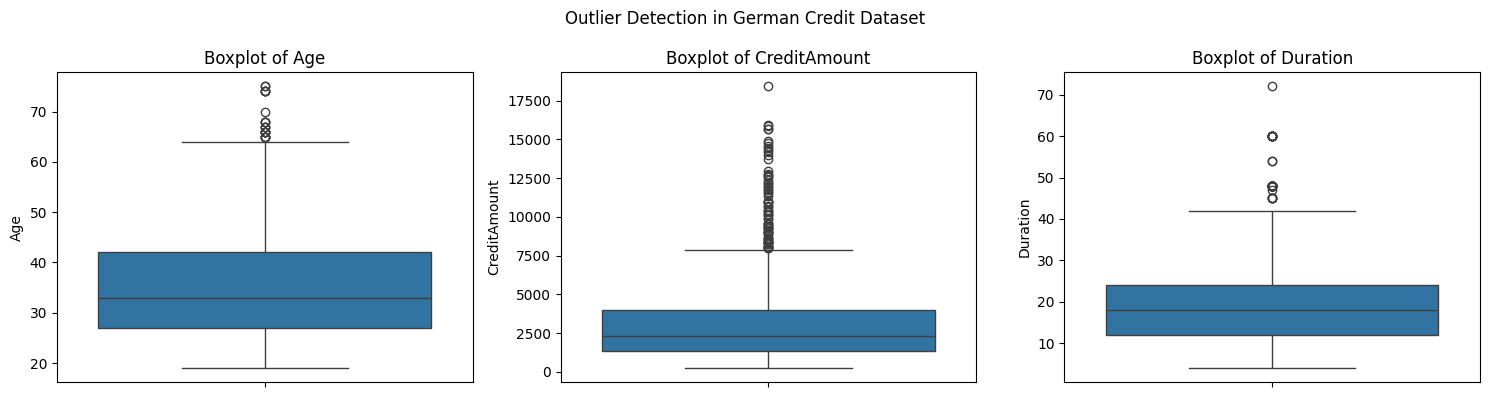

In [13]:
# Visualize outliers using boxplots

numerical_cols = ['Age', 'CreditAmount', 'Duration']

plt.figure(figsize=(15, 4))

for i, col in enumerate(numerical_cols, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(y=df[col])
    plt.title(f'Boxplot of {col}')
    plt.ylabel(col)

plt.suptitle('Outlier Detection in German Credit Dataset')
plt.tight_layout()
plt.show()


Credit Risk Distribution:


,Count
CreditRisk,
1,700
2,300


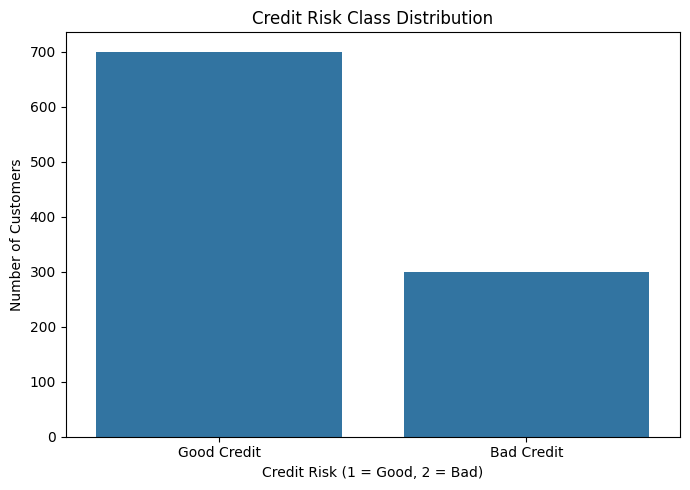


Credit Risk Percentage:
CreditRisk
1    70.0
2    30.0
Name: proportion, dtype: float64


In [14]:
# Check credit risk class distribution
risk_counts = df['CreditRisk'].value_counts().sort_index()

print("Credit Risk Distribution:")
display(risk_counts.to_frame(name='Count'))

# Create bar chart
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='CreditRisk',
    order=[1, 2]
)
plt.title('Credit Risk Class Distribution')
plt.xlabel('Credit Risk (1 = Good, 2 = Bad)')
plt.ylabel('Number of Customers')
plt.xticks([0, 1], ['Good Credit', 'Bad Credit'])

plt.tight_layout()
plt.show()

# Calculate percentages
risk_percentage = df['CreditRisk'].value_counts(
    normalize=True
).sort_index() * 100

print("\nCredit Risk Percentage:")
print(risk_percentage.round(2))

### Credit Risk Class Distribution

The chart shows that 70% of customers have good credit, while 30% have bad credit. This indicates that the dataset is imbalanced because there are more good-credit records than bad-credit records.

This imbalance could affect future analysis or machine learning models because the majority class has more records. I decided to keep the original distribution since this assignment focuses on data profiling and cleaning, not model training.

## 5. PII and Bias Risks

This section identifies potential privacy and bias risks in the German Credit Dataset, including sensitive customer attributes and imbalanced credit risk groups.

In [15]:
# Identify potential sensitive attributes

sensitive_cols = [
    'Age',
    'PersonalStatus',
    'ForeignWorker',
    'Telephone',
    'CreditAmount'
]

print("Potential Sensitive Attributes:")
display(df[sensitive_cols].head())

# Check distribution of foreign worker status
print("\nForeign Worker Distribution:")
display(df['ForeignWorker'].value_counts())

# Check credit risk class balance
print("\nCredit Risk Distribution (%):")
display(
    (df['CreditRisk'].value_counts(normalize=True) * 100)
    .round(2)
)


Potential Sensitive Attributes:


,Age,PersonalStatus,ForeignWorker,Telephone,CreditAmount
0,67,A93,A201,A192,1169
1,22,A92,A201,A191,5951
2,49,A93,A201,A191,2096
3,45,A93,A201,A191,7882
4,53,A93,A201,A191,4870



Foreign Worker Distribution:


,count
ForeignWorker,
A201,963
A202,37



Credit Risk Distribution (%):


,proportion
CreditRisk,
1,70.0
2,30.0


### PII and Bias Risks

The German Credit Dataset does not contain direct personal identifiers such as customer names, addresses, or actual telephone numbers. However, attributes such as Age, PersonalStatus, ForeignWorker, and CreditAmount may still contain sensitive information or create privacy concerns when combined.

The dataset also has a class imbalance, with 70% good-credit customers and 30% bad-credit customers. This could affect future credit risk analysis because the two groups are not equally represented.

To reduce these risks, sensitive attributes should be protected, and access to the dataset should be limited where appropriate. If the data is used for machine learning in the future, fairness across different demographic groups should also be evaluated. The original class distribution is kept for this assignment because the focus is on data profiling rather than model training.

## 6. Conclusion

Overall, the German Credit Dataset is suitable for basic credit risk analysis. Based on the initial profiling, the dataset has no missing values, and the numerical features were checked for invalid values and outliers.

The detected outliers were kept because they may represent real customer and loan information. The dataset also shows a class imbalance, with 70% good-credit customers and 30% bad-credit customers.

However, some limitations remain, including possible bias related to customer demographic information and the age of the dataset. Further checking would be needed before using the data for real banking decisions.

In conclusion, the dataset is suitable for exploratory credit risk analysis, but its limitations should be considered.